# EDA: IDS na danych OT (HAI 21.03)

Projekt ASI, s28129. Dane to pomiary ze stanowiska z prawdziwymi sterownikami PLC, zapisywane co sekundę. Procesy: P1 kocioł, P2 turbina, P3 uzdatnianie wody, P4 symulacja zapotrzebowania na moc. Końcówka `D` to polecenie położenia zaworu, a `Z` to jego rzeczywiste położenie.

Decyzje o danych opisuję na bieżąco, a na końcu jest ich tabela.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

files = {name: pd.read_csv(f'../data/01_raw/{name}.csv.gz') for name in ['train1', 'test1', 'test2']}
train = files['train1']
test = pd.concat([files['test1'], files['test2']], ignore_index=True)

labels = ['attack', 'attack_P1', 'attack_P2', 'attack_P3']
features = [c for c in train.columns if c not in ['time'] + labels]
print('Punkty pomiarowe:', len(features))
train.head()

Punkty pomiarowe: 79


,time,P1_B2004,P1_B2016,P1_B3004,P1_B3005,P1_B4002,P1_B4005,P1_B400B,P1_B4022,P1_FCV01D,...,P4_ST_GOV,P4_ST_LD,P4_ST_PO,P4_ST_PS,P4_ST_PT01,P4_ST_TT01,attack,attack_P1,attack_P2,attack_P3
0,2020-07-11 00:00:00,0.10121,1.29784,397.63785,1001.99799,33.6555,100.0,2847.02539,37.14706,100.0,...,16495.0,301.35992,305.03113,0,10052.0,27610.0,0,0,0,0
1,2020-07-11 00:00:01,0.10121,1.29692,397.63785,1001.99799,33.6555,100.0,2839.58520,37.14477,100.0,...,16402.0,297.43567,304.27161,0,10052.0,27610.0,0,0,0,0
2,2020-07-11 00:00:02,0.10121,1.29631,397.63785,1001.99799,33.6555,100.0,2833.26807,37.14325,100.0,...,16379.0,298.66534,303.89179,0,10050.0,27617.0,0,0,0,0
3,2020-07-11 00:00:03,0.10121,1.28685,397.63785,1001.99799,33.6555,100.0,2834.95264,37.11959,100.0,...,16422.0,298.06860,303.67474,0,10052.0,27614.0,0,0,0,0
4,2020-07-11 00:00:04,0.10121,1.28807,397.63785,1001.99799,33.6555,100.0,2832.70654,37.12265,100.0,...,16355.0,296.53137,303.22266,0,10052.0,27621.0,0,0,0,0


## 1. Jakość danych

In [2]:
pd.DataFrame({name: {
    'wiersze': len(d),
    'początek': d['time'].iloc[0],
    'braki': d[features].isna().sum().sum(),
    'duplikaty': d[features].duplicated().sum(),
    'rekordy ataku': d['attack'].sum(),
    'ataki': (d['attack'].diff() == 1).sum(),
} for name, d in files.items()}).T

,wiersze,początek,braki,duplikaty,rekordy ataku,ataki
train1,216001,2020-07-11 00:00:00,0,0,0,0
test1,43201,2020-07-07 15:00:00,0,0,629,5
test2,118801,2020-07-09 15:00:00,0,0,3449,20


In [3]:
unique = train[features].nunique()
constant = list(unique[unique == 1].index)
varies_in_test = [c for c in constant if test[c].nunique() > 1]
print('Stałe w train:', len(constant), ' zmienne w test:', varies_in_test)
print('P1_PCV02D != 12: rekordy', (test['P1_PCV02D'] != 12).sum(), ', w tym ataki', test.loc[test['P1_PCV02D'] != 12, 'attack'].sum())

print('Autokorelacja P1_PIT01 po 1 s:', round(train['P1_PIT01'].autocorr(1), 3))
print('Pierwszy wiersz train1 = ostatni wiersz test2:', train[features].iloc[0].equals(files['test2'][features].iloc[-1]))

attacks = test[test['attack'] == 1]
print('Udział ataków w testach:', round(test['attack'].mean(), 3))
print('Rekordy ataku bez etykiety procesu:', (attacks[labels[1:]].sum(axis=1) == 0).sum())

Stałe w train: 22  zmienne w test: ['P1_PCV02D', 'P2_Emerg', 'P2_OnOff']
P1_PCV02D != 12: rekordy 185 , w tym ataki 185
Autokorelacja P1_PIT01 po 1 s: 0.991
Pierwszy wiersz train1 = ostatni wiersz test2: True
Udział ataków w testach: 0.025
Rekordy ataku bez etykiety procesu: 154


Braków i duplikatów nie ma. Plik treningowy nie zawiera ataków, a pliki testowe zawierają ich 25.

- **D3:** dzielimy po plikach, a nie losowo, bo sąsiednie sekundy są prawie identyczne i losowy podział zawyżyłby wynik. Wiersz wspólny dla `train1` i `test2` usuwamy.
- **D4:** usuwamy 22 kolumny stałe w train, bo model nie nauczy się kolumny o jednej wartości. Trzy z nich zmieniają się w teście, ale głównie przy atakach.
- **D5:** jedyną etykietą jest `attack`. Etykiety procesów są niepełne, a `time` odzwierciedla tylko harmonogram testów, więc nie są cechami.
- **D8:** nie używamy accuracy, bo ataki to 2,5% rekordów, więc brak alarmów dałby 97,5%.

## 2. Statystyki i rozkłady

In [4]:
columns = [c for c in features if c not in constant]
train[columns].describe().T.sort_values('std').round(3).iloc[[0, 1, -2, -1]]

,count,mean,std,min,25%,50%,75%,max
P4_ST_FD,216001.0,-0.000,0.002,-0.009,-0.001,0.0,0.001,0.036
P4_HT_FD,216001.0,-0.000,0.002,-0.025,-0.000,-0.0,0.000,0.027
P3_LCP01D,216001.0,4600.318,5117.363,-8.000,72.000,1944.0,9632.000,13816.000
P3_LCV01D,216001.0,7201.445,6823.291,-288.000,-176.000,6416.0,14240.000,18416.000


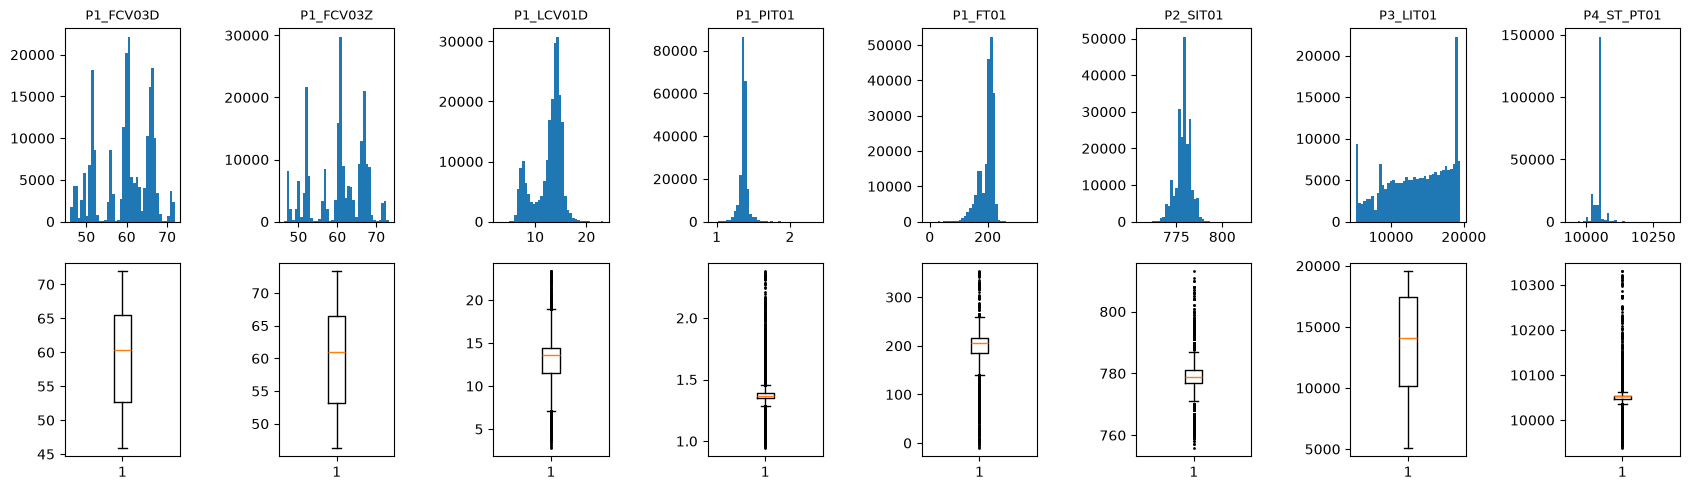

Największy udział rekordów z |z| > 5:
P4_HT_FD    0.0082
P1_FT01Z    0.0036
P1_PIT01    0.0032


In [5]:
selected = ['P1_FCV03D', 'P1_FCV03Z', 'P1_LCV01D', 'P1_PIT01', 'P1_FT01', 'P2_SIT01', 'P3_LIT01', 'P4_ST_PT01']
fig, axes = plt.subplots(2, len(selected), figsize=(17, 5))
for i, c in enumerate(selected):
    axes[0, i].hist(train[c], bins=40)
    axes[0, i].set_title(c, fontsize=9)
    axes[1, i].boxplot(train[c], flierprops={'markersize': 1})
plt.tight_layout()
plt.show()

scaled = (train[columns] - train[columns].mean()) / train[columns].std()
print('Największy udział rekordów z |z| > 5:')
print((scaled.abs() > 5).mean().sort_values(ascending=False).head(3).round(4).to_string())

Rozkłady mają kilka szczytów, bo instalacja pracuje w kilku stanach ustalonych. Skala zmiennych jest bardzo różna, więc w etapie 3 potrzebna będzie standaryzacja.

- **D6:** nie usuwamy wartości odstających, bo w `train1` nie ma ataków, więc są to prawdziwe, rzadkie stany instalacji.

## 3. Zmienne kategoryczne

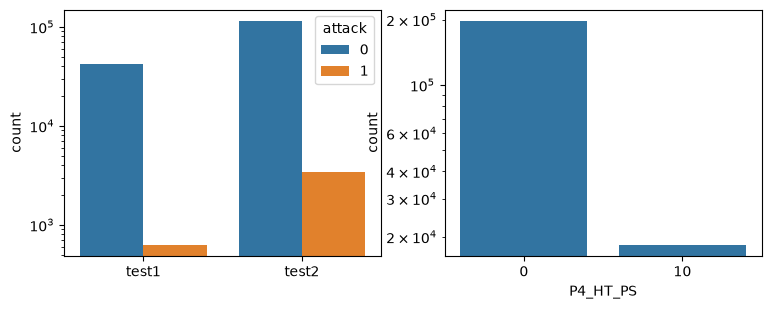

P4_ST_PS,0,50
P4_HT_PS,,
0,140936,0
10,0,21066


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
sns.countplot(data=test, x=np.where(test.index < len(files['test1']), 'test1', 'test2'), hue='attack', ax=axes[0])
sns.countplot(data=train, x='P4_HT_PS', ax=axes[1])
for ax in axes:
    ax.set_yscale('log')
plt.show()

pd.crosstab(test['P4_HT_PS'], test['P4_ST_PS'])

## 4. Korelacje i pary zmiennych

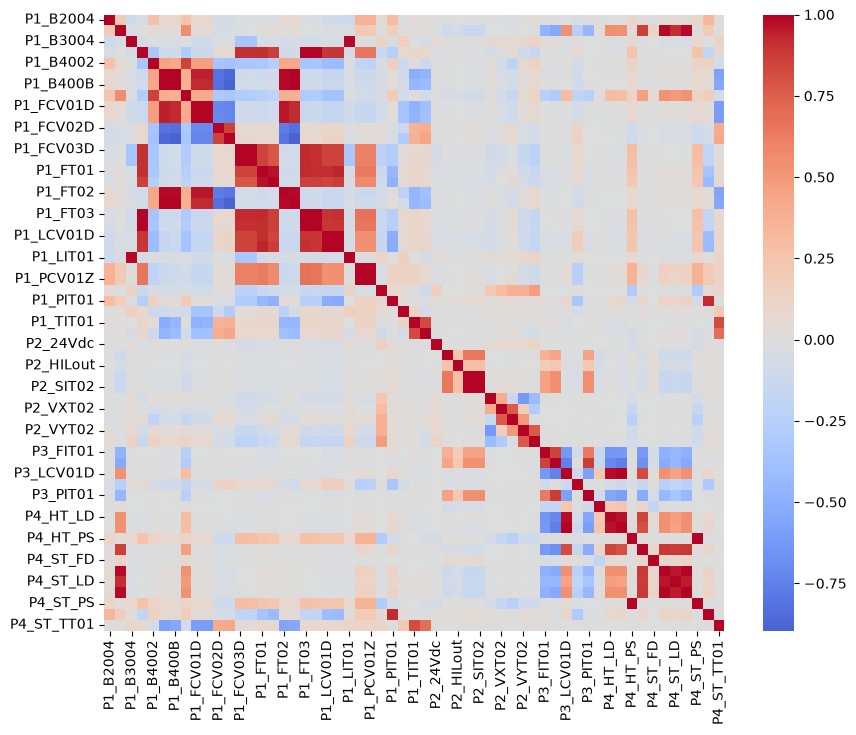

Pary |r| > 0.99: 13
FCV03, r = 0.997
Różnica D - Z powyżej 5 odchyleń: {0: 0.0001, 1: 0.0483}


In [7]:
corr = train[columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.show()

pairs = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print('Pary |r| > 0.99:', (pairs > 0.99).sum())

diff = train['P1_FCV03D'] - train['P1_FCV03Z']
z = ((test['P1_FCV03D'] - test['P1_FCV03Z'] - diff.mean()) / diff.std()).abs()
print('FCV03, r =', round(train['P1_FCV03D'].corr(train['P1_FCV03Z']), 3))
print('Różnica D - Z powyżej 5 odchyleń:', (z > 5).groupby(test['attack']).mean().round(4).to_dict())

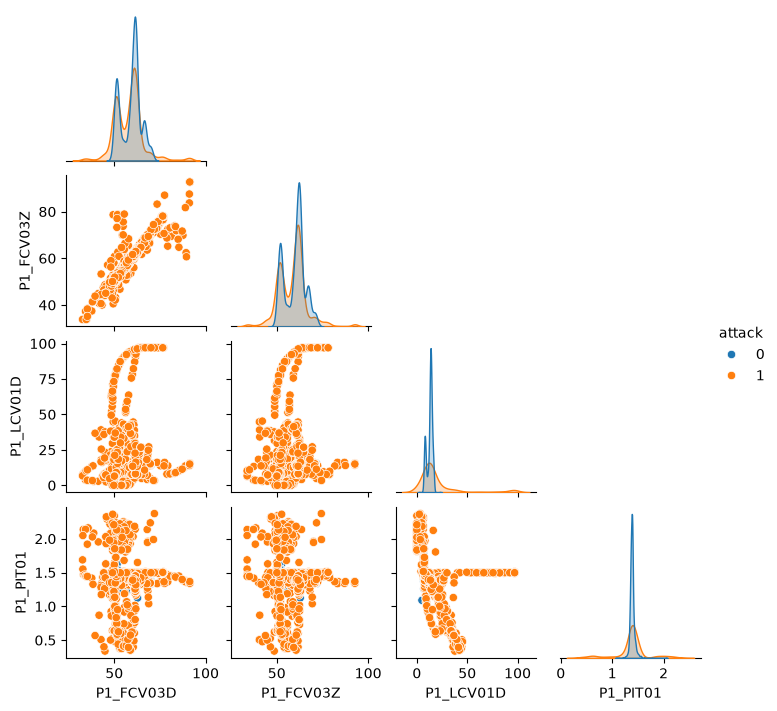

In [8]:
sample = pd.concat([test[test['attack'] == v].sample(1500, random_state=42) for v in (0, 1)])
sns.pairplot(sample[selected[:4] + ['attack']], hue='attack', corner=True, height=1.8)
plt.show()

- **D7:** usuwamy tylko `P4_ST_PS`, bo to dokładna kopia `P4_HT_PS` (0→0, 10→50). Innych skorelowanych kolumn nie usuwamy, bo rozjazd polecenia i położenia zaworu to objaw ataku.

Ataki często leżą poza główną chmurą punktów, ale mocno na nią zachodzą. Pairplot pokazuje 4 zmienne i równą liczbę rekordów obu klas, bo przy 2,5% ataków byłyby niewidoczne.

## 5. Decyzje

Po decyzjach zostaje 56 cech: 79 − 22 stałe − `P4_ST_PS`.

| # | Decyzja | Dlaczego | Przykład |
|---|---|---|---|
| D1 | HAI 21.03 zamiast CIC-IDS2017 | projekt dotyczy OT, a CIC-IDS2017 to ruch biurowy | realne PLC, `train1` bez ataków |
| D2 | tylko `train1`, `test1`, `test2` | tyle wystarczy i dane są małe | 60 h normalnej pracy, 25 ataków, 53 MB |
| D3 | podział po plikach, nie losowy | sąsiednie sekundy są prawie identyczne | autokorelacja 0,99 po 1 s |
| D4 | usuwamy 22 kolumny stałe w train | jedna wartość nie uczy modelu | `P1_PP02D` zawsze 1 |
| D5 | etykieta to tylko `attack`, `time` nie jest cechą | etykiety procesów są niepełne, czas to harmonogram testów | 154 rekordy ataku bez procesu |
| D6 | zostawiamy wartości odstające | w train to prawdziwe stany instalacji | `P4_HT_FD`: 0,8% powyżej 5 odchyleń |
| D7 | usuwamy tylko `P4_ST_PS` | to kopia, a pozostałe korelacje niosą sygnał ataku | `FCV03`: rozjazd w 0,01% normalnych i 4,8% ataków |
| D8 | bez accuracy | ataki to 2,5% rekordów | brak alarmów daje 97,5% |

**Etap 3:** usunąć kolumny według D3, D4, D7, podzielić dane po plikach i dopasować standaryzację tylko na `train1`.